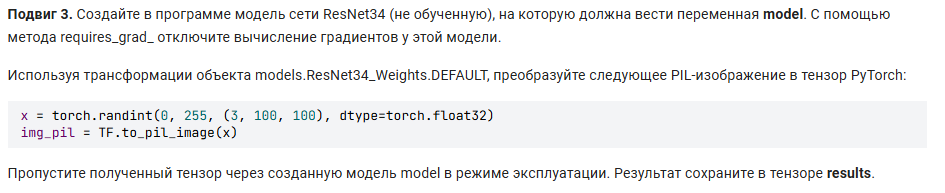

In [10]:
import torch
from torchvision import models
import torchvision.transforms.functional as TF

# тензор x и img_pil в программе не менять
x = torch.randint(0, 255, (3, 100, 100), dtype=torch.float32) 
img_pil = TF.to_pil_image(x)

resnet_weights = models.ResNet34_Weights.DEFAULT

transform = resnet_weights.transforms()

img_tr = transform(img_pil).unsqueeze(0)

# здесь продолжайте программу

model = models.resnet34()
model.eval()
model.requires_grad_(False)
results = model(img_tr).squeeze(0)

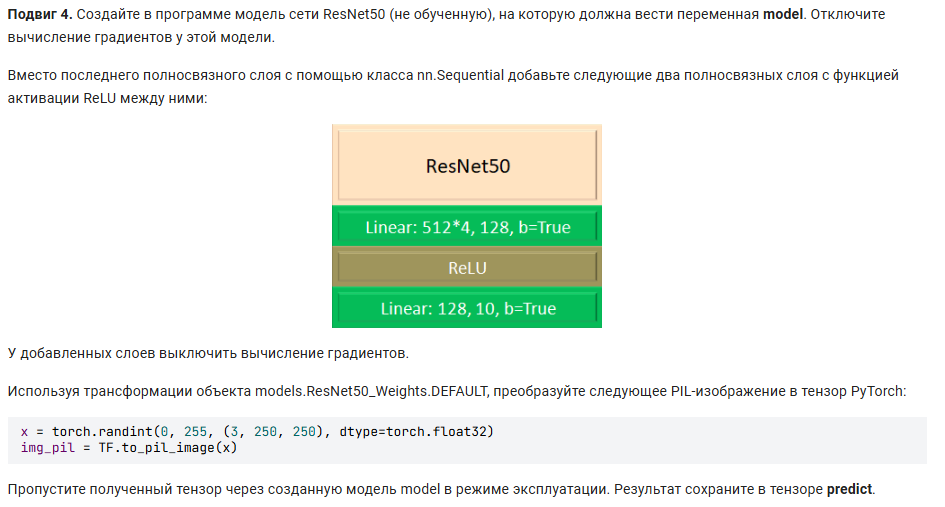

In [19]:
import torch
import torch.nn as nn
from torchvision import models
import torchvision.transforms.functional as TF

# тензор x и img_pil в программе не менять
x = torch.randint(0, 255, (3, 250, 250), dtype=torch.float32)
img_pil = TF.to_pil_image(x)
transform = models.ResNet50_Weights.DEFAULT.transforms()
img_tr = transform(img_pil).unsqueeze(0)

# здесь продолжайте программу
model = models.resnet50()
model.requires_grad_(False)

head = nn.Sequential(
    nn.Linear(512*4, 128, bias=True),
    nn.ReLU(),
    nn.Linear(128, 10, bias=True)
)

model.fc = head
head.requires_grad_(False)

model.eval()
predict = model(img_tr)
predict

tensor([[  9.0565,  -2.5332,  12.3303, -12.7408,   4.5647,   3.2533,  -6.2655,
           5.8383,  -6.5206,  18.3148]])

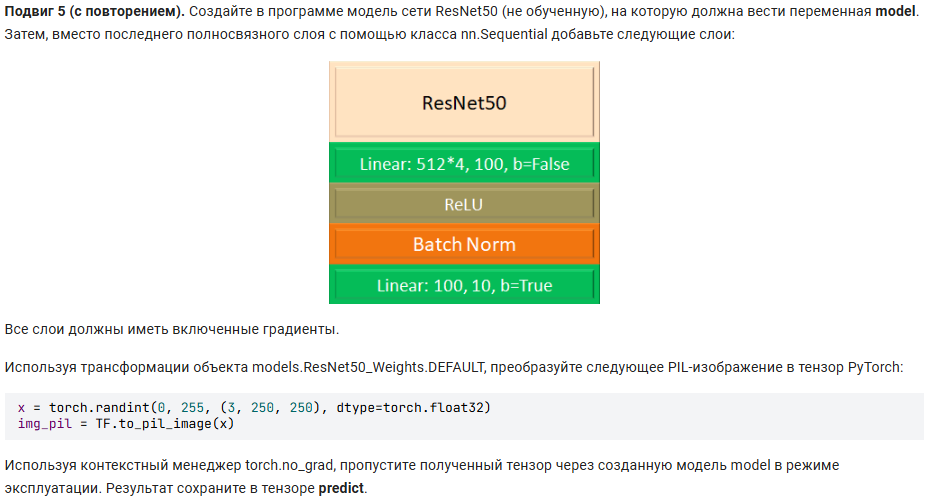

In [31]:
import torch
import torch.nn as nn
from torchvision import models
import torchvision.transforms.functional as TF

# тензор x и img_pil в программе не менять
x = torch.randint(0, 255, (3, 250, 250), dtype=torch.float32)
img_pil = TF.to_pil_image(x)

transform = models.ResNet50_Weights.DEFAULT.transforms()
img_tr = transform(img_pil).unsqueeze(0)

# здесь продолжайте программу
model = models.resnet50()

model.fc = nn.Sequential(
    nn.Linear(512*4, 100, bias=False),
    nn.ReLU(inplace=True),
    nn.BatchNorm1d(100),
    nn.Linear(100, 10, bias=True)
)

model.eval()

with torch.no_grad():
    predict = model(img_tr)
# predict

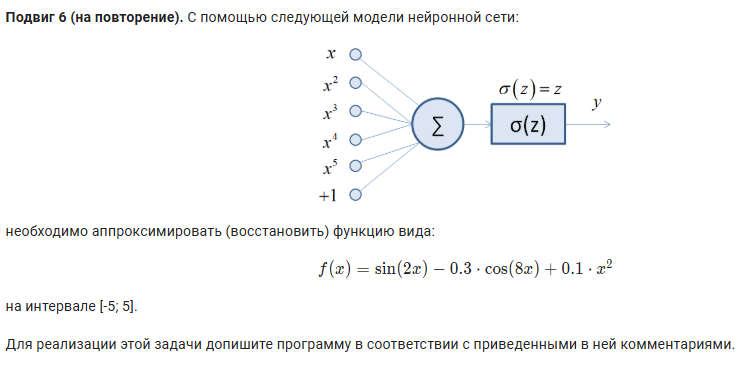

In [52]:
import torch
import torch.utils.data as data
import torch.nn as nn
import torch.optim as optim

class FuncModel(nn.Module):
    def __init__(self):
        super().__init__()
        # модель однослойной полносвязной нейронной сети:
        # 1-й слой: число входов 5 (x, x^2, x^3, x^4, x^5), число нейронов 1
        self.layer = nn.Linear(5, 1, bias=True)

    def forward(self, x):
        x.unsqueeze_(-1)
        xx = torch.cat([x, x ** 2, x ** 3, x ** 4, x ** 5], dim=1)
        y = self.layer(xx)
        return y

torch.manual_seed(1)

model = FuncModel() # создать модель FuncModel

epochs = 20 # число эпох обучения
batch_size = 16 # размер батча

# данные обучающей выборки (значения функции)
data_x = torch.arange(-5, 5, 0.05) #тензоры data_x, data_y не менять
data_y = torch.sin(2 * data_x) - 0.3 * torch.cos(8 * data_x) + 0.1 * data_x ** 2

ds = data.TensorDataset(data_x, data_y) # создание dataset
d_train, d_val =  data.random_split(ds, (0.7, 0.3)) # разделить ds на две части в пропорции: 70% на 30%
train_data = data.DataLoader(d_train, batch_size=batch_size, shuffle=True) # создать объект класса DataLoader для d_train с размером пакетов batch_size и перемешиванием образов выборки
train_data_val = data.DataLoader(d_val, batch_size=batch_size, shuffle=False) # создать объект класса DataLoader для d_val с размером пакетов batch_size и без перемешивания образов выборки

optimizer = optim.RMSprop(params=model.parameters(), lr=0.01) # создать оптимизатор RMSprop для обучения модели с шагом обучения 0.01
loss_func = nn.MSELoss() # создать функцию потерь с помощью класса MSELoss

loss_lst_val = []  # список значений потерь при валидации
loss_lst = []  # список значений потерь при обучении

for _e in range(epochs):
    # перевести модель в режим обучения
    model.train()
    loss_mean = 0 # вспомогательные переменные для вычисления среднего значения потерь при обучении
    lm_count = 0

    for x_train, y_train in train_data:
        optimizer.zero_grad()
        predict = model(x_train).squeeze(1) # вычислить прогноз модели для данных x_train
        # print(predict.shape, y_train.shape)
        loss = loss_func(predict, y_train) # вычислить значение функции потерь
        loss.backward()

        # сделать один шаг градиентного спуска для корректировки параметров модели
        optimizer.step()

        # вычисление среднего значения функции потерь по всей выборке
        lm_count += 1
        loss_mean = 1 / lm_count * loss.item() + (1 - 1 / lm_count) * loss_mean

    # валидация модели
    # перевести модель в режим эксплуатации
    model.eval()
    Q_val = 0
    count_val = 0

    for x_val, y_val in train_data_val:
        with torch.no_grad():
            # для x_val, y_val вычислить потери с помощью функции loss_func
            predict = model(x_val).squeeze(1)
            loss = loss_func(predict, y_val)
            count_val += 1

    # сохранить средние потери, вычисленные по выборке валидации, в переменной Q_val
            Q_val = 1 / count_val * loss.item() + (1 - 1 / count_val) * Q_val

    loss_lst.append(loss_mean)
    loss_lst_val.append(Q_val)

# перевести модель в режим эксплуатации
model.eval()

# выполнить прогноз модели по всем данным выборки (ds.data)
predict = model(data_x).squeeze(1)
Q = loss_func(predict, data_y).item() # вычислить потери с помощью loss_func по всем данным выборки ds; значение Q сохранить в виде вещественного числа
Q

17.375402450561523